# K-Drama AI - Project 1: Supervised Learning
## Will a viewer like this K-Drama?

**Course:** AI Fundamentals - Final Project 1 (Practice 8 worksheet) &nbsp;|&nbsp; **Variant 21 - Movie preference**, adapted to Korean dramas

**Team (QAIRU): Shakenova Aruzhan, Qabir Madina, Shahap Aizere, Zholdaspek Dana**

| Item | Our choice |
|---|---|
| Object (one row) | one real review: one viewer scores one K-Drama on MyDramaList |
| Target | `liked` = 1 if the viewer's own overall score is 8 or more (out of 10), else 0 |
| Type | binary classification |
| Variant features | `genre_score`, `runtime_min`, `popularity` |
| Extra features | `public_rating`, `episodes`, `year` |
| Models | Logistic Regression and Random Forest (scikit-learn Pipelines) |

**How we adapted the variant.** Variant 21 says: *predict "likes movie" from genre score, runtime and popularity; no exact
source established*. We replaced movies with Korean dramas and found a **real** public dataset with genuine individual
viewer scores, so **no label in this notebook is simulated**. The original 1-10 score is grouped into two classes
(documented below). This adaptation of the task should be confirmed with the instructor, as the worksheet asks.

The notebook follows the worksheet sequence **DATA -> SPLIT -> PREPARE -> TRAIN -> VALIDATE -> TEST -> DECIDE**.

## Step 1 - Import the libraries

`pandas` and `numpy` hold the data, `matplotlib` draws the charts, and `scikit-learn` gives us the split,
the leakage-safe `Pipeline`, both classifiers and the metrics. Nothing is trained in this cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

SEED = 42
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Libraries are ready.")

Libraries are ready.


## Step 2 - Download the REAL data and build the table

**Sources (both scraped from MyDramaList.com and published on Kaggle):**

* **Source A** - Chanon Charuchinda (2023). *Korean Drama from 2015-2023 with Actors & Reviews*. Kaggle. Licence: CC0 Public Domain.
  <https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist>
  We use `korean_drama.csv` (drama metadata) and `reviews.csv` (10,625 reviews written by real viewers, each with an `overall_score`).
* **Source B** - Noor Rizki (2023). *Top Korean Drama List (~1500)*. Kaggle. Licence: not stated ("Unknown").
  <https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500>
  We use `kdrama_list.csv` for the genres and the public MyDramaList score of each drama.

The cell below downloads the files directly (no Kaggle account is needed), joins them by title and year, and builds two tables:
`dramas` (one row per drama) and `reviews` (one row per viewer review). **Nothing is generated randomly.**

**The most important feature - `genre_score`.** The variant asks for a "genre score". We define it for each review as
*the average score that the same viewer gave to OTHER dramas that share at least one genre with this drama*.
The review we want to predict is never included in this average, so the feature does not contain the answer.
If the viewer has no other review with a shared genre, the value is missing (NaN). These are real missing values.

In [2]:
"""K-Drama AI - data loading and feature engineering.

This single file builds BOTH tables used in the project:

* the DRAMA table   (one row = one K-Drama)            -> Project 2, website catalogue
* the REVIEW table  (one row = one viewer x one drama) -> Project 1

Everything comes from two public Kaggle datasets that were scraped from
MyDramaList (MDL). Nothing in these tables is simulated.

Source A  Chanon Charuchinda (2023), "Korean Drama from 2015-2023 with Actors & Reviews",
          Kaggle, licence CC0: Public Domain.
          https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist
          files used: korean_drama.csv (1,752 dramas), reviews.csv (10,625 viewer reviews)

Source B  Noor Rizki (2023), "Top Korean Drama List (~1500)", Kaggle, licence not stated ("Unknown").
          https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500
          file used: kdrama_list.csv (1,647 dramas with genres and the public MDL score)
"""

import io
import re
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

KAGGLE_DOWNLOAD = "https://www.kaggle.com/api/v1/datasets/download/"
SOURCE_A = "chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist"
SOURCE_B = "noorrizki/top-korean-drama-list-1500"
RAW_FILES = {
    "korean_drama.csv": SOURCE_A,
    "reviews.csv": SOURCE_A,
    "kdrama_list.csv": SOURCE_B,
}

LIKE_THRESHOLD = 8.0          # a viewer "likes" a drama when their own overall score is >= 8 / 10
MISSING_RANK_CODE = 99999     # Source A writes 99999 when MDL shows no rank; we treat it as missing


def download_raw(raw_dir="data/raw") -> Path:
    """Download the three raw CSV files (only the ones that are not on disk yet)."""
    raw_dir = Path(raw_dir)
    raw_dir.mkdir(parents=True, exist_ok=True)
    for slug in sorted({s for f, s in RAW_FILES.items() if not (raw_dir / f).exists()}):
        request = urllib.request.Request(KAGGLE_DOWNLOAD + slug, headers={"User-Agent": "python-urllib"})
        with urllib.request.urlopen(request, timeout=120) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        for name in archive.namelist():
            if name in RAW_FILES:
                (raw_dir / name).write_bytes(archive.read(name))
    return raw_dir


def _key(text) -> str:
    """Normalise a title so that the two sources can be joined ('Move to Heaven' -> 'movetoheaven')."""
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def build_drama_table(raw_dir="data/raw") -> pd.DataFrame:
    """One row per drama, with real MDL metadata and a drama-level genre score."""
    raw_dir = Path(raw_dir)
    meta = pd.read_csv(raw_dir / "korean_drama.csv")
    genre_list = pd.read_csv(raw_dir / "kdrama_list.csv")

    meta["join_key"] = meta["drama_name"].map(_key) + meta["year"].astype(str)
    genre_list["join_key"] = genre_list["Name"].map(_key) + genre_list["Year"].astype(str)
    df = meta.merge(genre_list[["join_key", "Genre", "Score"]], on="join_key", how="inner")

    dramas = pd.DataFrame({
        "drama_id": df["kdrama_id"],
        "title": df["drama_name"].str.strip(),
        "year": df["year"].astype(int),
        "genres": df["Genre"].map(lambda g: "|".join(x.strip() for x in str(g).split(",") if x.strip())),
        "runtime_min": (df["duration"] / 60).round(1),               # seconds -> minutes per episode
        "episodes": df["tot_eps"].astype(float),
        "popularity_rank": df["pop"].where(df["pop"] != MISSING_RANK_CODE).astype(float),
        "public_rating": df["Score"].astype(float),                   # MDL community average, 0-10
    })

    # Drama-level genre score: how well-rated the drama's genres are on MDL in general.
    # Step 1: average public rating of every genre. Step 2: average those values over the drama's genres.
    exploded = dramas.assign(genre=dramas["genres"].str.split("|")).explode("genre")
    genre_mean = exploded.groupby("genre")["public_rating"].mean()
    dramas["genre_score"] = (
        exploded["genre"].map(genre_mean).groupby(level=0).mean().round(3)
    )
    return dramas.sort_values("popularity_rank", na_position="last").reset_index(drop=True)


def build_review_table(drama_table: pd.DataFrame, raw_dir="data/raw") -> pd.DataFrame:
    """One row per real viewer review, with the binary target and a viewer-level genre score."""
    reviews = pd.read_csv(Path(raw_dir) / "reviews.csv",
                          usecols=["user_id", "title", "overall_score"])
    dramas = drama_table.assign(title_key=drama_table["title"].map(_key))
    dramas = dramas.drop_duplicates("title_key", keep=False)          # drop ambiguous (repeated) titles
    reviews["title_key"] = reviews["title"].map(_key)
    df = reviews.merge(dramas.drop(columns=["title", "genre_score"]), on="title_key", how="inner")
    df = df.drop_duplicates(["user_id", "drama_id"]).reset_index(drop=True)

    # Viewer-level genre score = the mean score the SAME viewer gave to OTHER dramas that share
    # at least one genre with this drama. The review being predicted is never included, so the
    # feature does not contain the target. No other matching review -> missing value (NaN).
    genre_sets = df["genres"].str.split("|").map(set)
    scores = df["overall_score"].to_numpy()
    genre_score = np.full(len(df), np.nan)
    for _, idx in df.groupby("user_id").indices.items():
        if len(idx) < 2:
            continue
        for i in idx:
            others = [scores[j] for j in idx if j != i and genre_sets[i] & genre_sets[j]]
            if others:
                genre_score[i] = np.mean(others)

    out = pd.DataFrame({
        "viewer_id": df["user_id"],
        "drama_id": df["drama_id"],
        "title": df["title"],
        "genres": df["genres"],
        "genre_score": np.round(genre_score, 3),
        "runtime_min": df["runtime_min"],
        "popularity_rank": df["popularity_rank"],
        "public_rating": df["public_rating"],
        "episodes": df["episodes"],
        "year": df["year"],
        "viewer_score": df["overall_score"],
        "liked": (df["overall_score"] >= LIKE_THRESHOLD).astype(int),
    })
    return out


def load_tables(raw_dir="data/raw"):
    """Download (if needed) and build both tables. Returns (drama_table, review_table)."""
    download_raw(raw_dir)
    dramas = build_drama_table(raw_dir)
    return dramas, build_review_table(dramas, raw_dir)

dramas, reviews = load_tables("data/raw")
print("drama table :", dramas.shape)
print("review table:", reviews.shape)

drama table : (1094, 9)
review table: (9840, 12)


## Step 3 - Inspect the data

We look at the size, the first rows, the data types, the missing values and the class balance.

In [3]:
MODEL_COLUMNS = ["genre_score", "runtime_min", "popularity_rank", "public_rating", "episodes", "year"]

print("Dataset dimensions (rows, columns):", reviews.shape)
print("Different viewers:", reviews["viewer_id"].nunique(), "| different dramas:", reviews["drama_id"].nunique())
display(reviews.drop(columns=["viewer_id", "drama_id"]).head())

feature_info = pd.DataFrame({
    "column": MODEL_COLUMNS + ["liked"],
    "dtype": [str(reviews[c].dtype) for c in MODEL_COLUMNS + ["liked"]],
    "meaning": [
        "viewer's mean score (1-10) for OTHER dramas sharing a genre with this one; NaN = no such history",
        "length of one episode in minutes",
        "MyDramaList popularity rank (1 = most popular drama)",
        "public MyDramaList rating of the drama (average of all users, 0-10)",
        "number of episodes",
        "release year",
        "TARGET: 1 if this viewer's overall score >= 8, else 0",
    ],
})
display(feature_info)

Dataset dimensions (rows, columns): (9840, 12)
Different viewers: 4277 | different dramas: 1066


,title,genres,genre_score,runtime_min,popularity_rank,public_rating,episodes,year,viewer_score,liked
0,Our Dating Sim,Business|Romance,8.091,15.0,569.0,8.0,8.0,2023,9.0,1
1,The Director Who Buys Me Dinner,Romance|Fantasy,8.286,15.0,679.0,7.4,10.0,2022,7.0,0
2,Unlock My Boss,Thriller|Mystery|Comedy|Fantasy,7.708,60.0,1088.0,8.0,12.0,2022,8.5,1
3,Roommates of Poongduck 304,Business|Romance,8.091,25.0,570.0,7.9,8.0,2022,9.0,1
4,The Golden Spoon,Psychological|Drama|Fantasy|Supernatural,8.036,80.0,658.0,8.1,16.0,2022,8.0,1


,column,dtype,meaning
0,genre_score,float64,viewer's mean score (1-10) for OTHER dramas sh...
1,runtime_min,float64,length of one episode in minutes
2,popularity_rank,float64,MyDramaList popularity rank (1 = most popular ...
3,public_rating,float64,public MyDramaList rating of the drama (averag...
4,episodes,float64,number of episodes
5,year,int64,release year
6,liked,int64,"TARGET: 1 if this viewer's overall score >= 8,..."


In [4]:
print("Missing values per column:")
print(reviews[MODEL_COLUMNS + ["liked"]].isna().sum().to_string())
print("\nShare of missing genre_score:", round(reviews["genre_score"].isna().mean(), 3))

print("\nClass counts:      ", reviews["liked"].value_counts().sort_index().to_dict())
print("Class proportions: ", reviews["liked"].value_counts(normalize=True).sort_index().round(3).to_dict())
display(reviews[MODEL_COLUMNS].describe().round(2))

Missing values per column:
genre_score        3253
runtime_min           0
popularity_rank       0
public_rating         0
episodes              0
year                  0
liked                 0

Share of missing genre_score: 0.331

Class counts:       {0: 4149, 1: 5691}
Class proportions:  {0: 0.422, 1: 0.578}


,genre_score,runtime_min,popularity_rank,public_rating,episodes,year
count,6587.00,9840.00,9840.00,9840.00,9840.00,9840.00
mean,7.58,50.55,1401.16,7.93,18.66,2019.08
std,1.49,22.07,1524.58,0.51,16.82,2.29
min,1.00,2.00,1.00,6.50,1.00,2015.00
25%,6.75,35.00,338.50,7.60,12.00,2017.00
50%,7.75,60.00,887.00,7.90,16.00,2019.00
75%,8.56,70.00,1901.00,8.30,17.00,2021.00
max,10.00,100.00,10980.00,9.20,150.00,2023.00


**What the result means**

* The table has **9,840 real reviews** written by **4,277 viewers** about **1,066 dramas**.
* All model columns are numerical. Only `genre_score` has missing values: **3,253 rows
  (33.1%)**. They belong to viewers with no other review of a similar genre (mostly viewers with one review).
  We did **not** add artificial missing values - the worksheet's worked example says missingness should reflect the actual dataset. The gaps are filled later *inside* the pipeline.
* Class balance: **57.8% liked (1)** and **42.2% not liked (0)**. The classes are a little unbalanced but not extreme,
  so F1 and ROC-AUC are more informative than accuracy alone.
* **Binary grouping:** the source has scores from 1 to 10 in steps of 0.5. We code 8.0-10 as class 1 ("liked") and 1-7.5 as class 0. The median score is 8, so this threshold splits viewers into "clearly positive" and "the rest".
* **Limitation:** people who write reviews are not typical viewers. They choose what to watch and review, so the data is not a random sample.

## Step 4 - Exploratory Data Analysis (four figures)

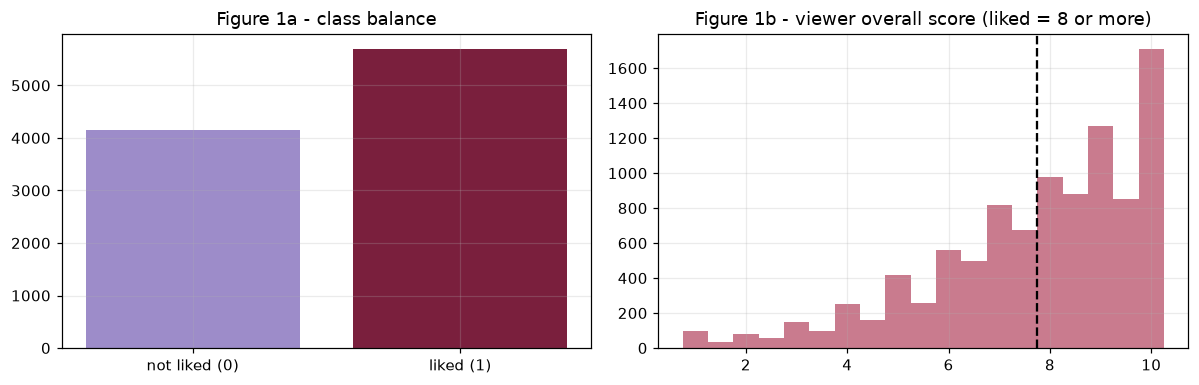

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = reviews["liked"].value_counts().sort_index()
axes[0].bar(["not liked (0)", "liked (1)"], counts.values, color=["#9d8cc9", "#7a1f3d"])
axes[0].set_title("Figure 1a - class balance")
axes[1].hist(reviews["viewer_score"], bins=np.arange(0.75, 10.75, 0.5), color="#c97b8e")
axes[1].axvline(7.75, color="black", linestyle="--")
axes[1].set_title("Figure 1b - viewer overall score (liked = 8 or more)")
plt.tight_layout(); plt.show()

**Figure 1.** Reviewers are generous: most scores are 7 or higher and the most common values are 8-10.
The dashed line is our threshold. A model that always answers "liked" would already be right more than half of the time,
so we must compare our models with this simple baseline.

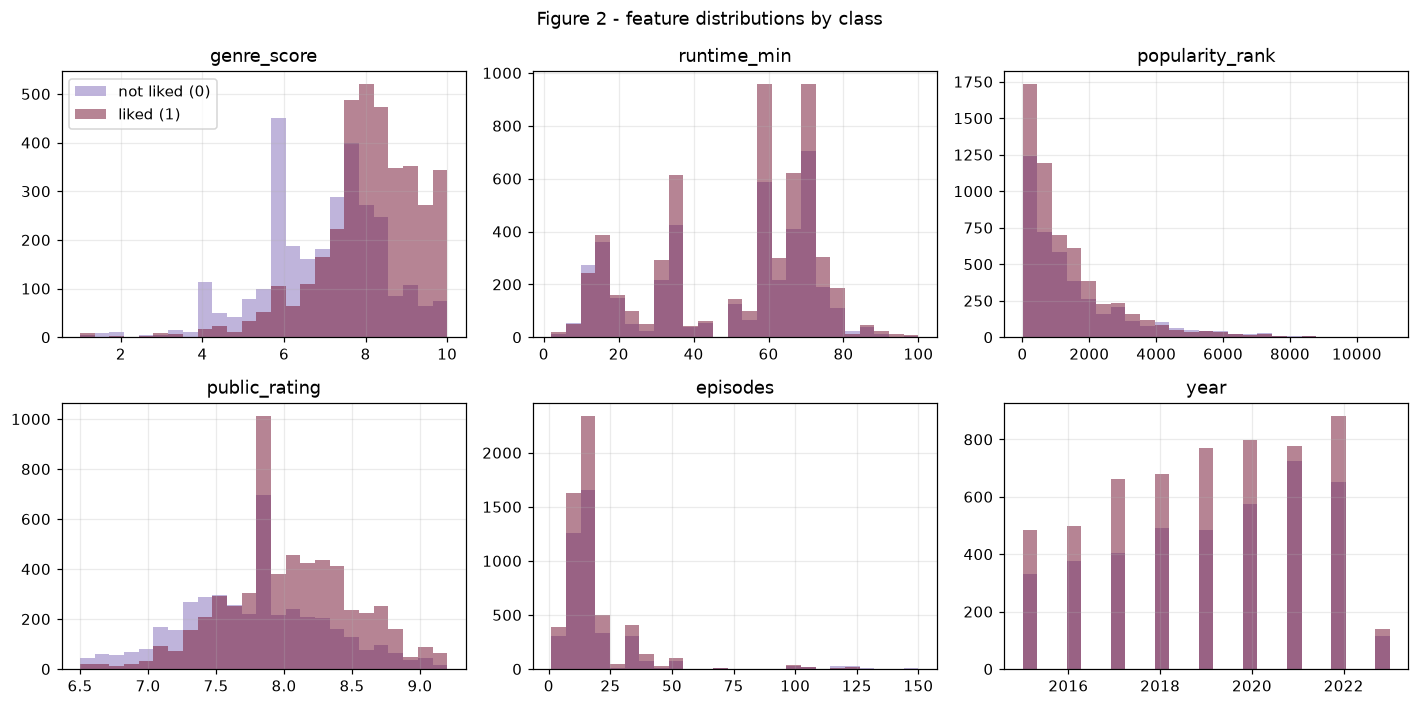

In [6]:
liked = reviews["liked"] == 1
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), MODEL_COLUMNS):
    bins = np.histogram_bin_edges(reviews[col].dropna(), bins=25)
    ax.hist(reviews.loc[~liked, col].dropna(), bins=bins, alpha=0.65, color="#9d8cc9", label="not liked (0)")
    ax.hist(reviews.loc[liked, col].dropna(), bins=bins, alpha=0.55, color="#7a1f3d", label="liked (1)")
    ax.set_title(col)
axes[0, 0].legend()
fig.suptitle("Figure 2 - feature distributions by class")
plt.tight_layout(); plt.show()

**Figure 2.** (1) `genre_score`: liked reviews are shifted to the right - viewers who usually enjoy a genre tend to like the next drama of that genre.
(2) `public_rating`: liked reviews are more frequent for highly rated dramas. (3) `runtime_min` has two peaks: short web dramas (10-25 minutes)
and normal TV dramas (60-70 minutes). (4) `popularity_rank` and `episodes` are strongly right-skewed, and the features have very different scales
(years are about 2,000, ranks go up to 10,000) - this is why we scale them for Logistic Regression.

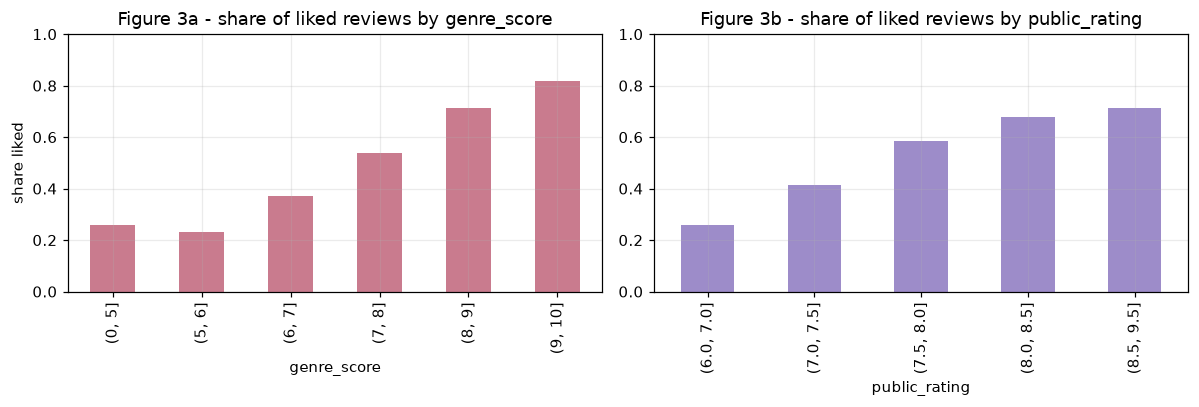

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
genre_bins = pd.cut(reviews["genre_score"], bins=[0, 5, 6, 7, 8, 9, 10])
reviews.groupby(genre_bins, observed=True)["liked"].mean().plot(kind="bar", ax=axes[0], color="#c97b8e")
axes[0].set_title("Figure 3a - share of liked reviews by genre_score")
axes[0].set_ylabel("share liked"); axes[0].set_ylim(0, 1)
rating_bins = pd.cut(reviews["public_rating"], bins=[6, 7, 7.5, 8, 8.5, 9.5])
reviews.groupby(rating_bins, observed=True)["liked"].mean().plot(kind="bar", ax=axes[1], color="#9d8cc9")
axes[1].set_title("Figure 3b - share of liked reviews by public_rating")
axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Figure 3.** The share of "liked" grows step by step with both `genre_score` and `public_rating`.
The relationship is clear but not perfect: even in the best bins some viewers do not like the drama. We should expect a useful model, not a perfect one.

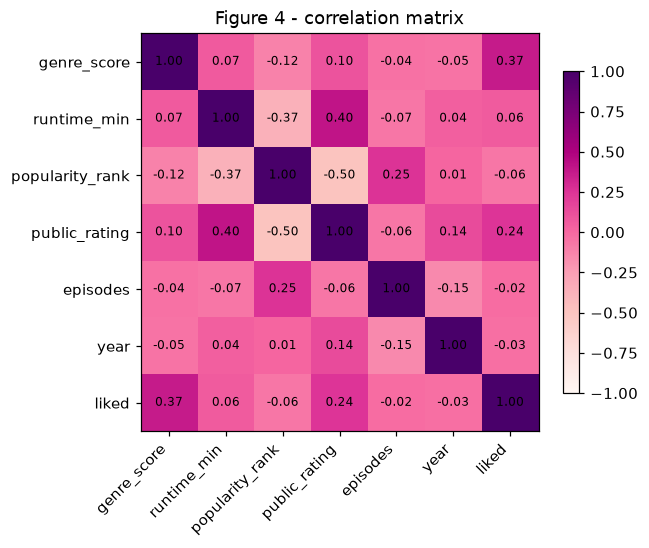

In [8]:
corr = reviews[MODEL_COLUMNS + ["liked"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdPu", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.8)
ax.set_title("Figure 4 - correlation matrix")
plt.tight_layout(); plt.show()

**Figure 4.** `genre_score` and `public_rating` have the strongest correlation with the target. `public_rating` and `popularity_rank`
are negatively correlated (popular dramas have a small rank number and a higher rating). Correlation shows association only, not cause.

## Step 5 - Feature engineering and the 80/20 split (before any fitted preprocessing)

**Feature engineering.** `popularity_rank` is very skewed, so we use `popularity_log = log10(popularity_rank)`.
This is a row-by-row formula: it learns nothing from other rows, so it is safe to apply before the split.

**Why a *grouped* split?** One viewer can write many reviews, and `genre_score` is built from the viewer's other reviews.
If the same viewer were in both the training and the test set, the test would be too easy (a hidden form of data leakage).
So we keep **all reviews of one viewer on the same side**. `StratifiedGroupKFold` with 5 folds creates five parts with
(almost) the same class balance and no shared viewers; we take one part (20%) as the test set and the other four (80%) for training.
A plain `train_test_split(stratify=y)` cannot keep the viewers together.

**Why `shuffle=False`?** Without shuffling the procedure has no randomness at all, so everybody gets exactly the same split,
in every version of scikit-learn. (We checked: with scikit-learn 1.6 the shuffled variant returned a poorly stratified test fold -
51% liked instead of 58% - while the non-shuffled variant is identical in versions 1.6 and 1.9.)

In [9]:
data = reviews.copy()
data["popularity_log"] = np.log10(data["popularity_rank"])

FEATURES = ["genre_score", "runtime_min", "popularity_log", "public_rating", "episodes", "year"]
X = data[FEATURES]
y = data["liked"]
viewers = data["viewer_id"]

outer = StratifiedGroupKFold(n_splits=5, shuffle=False)
train_idx, test_idx = next(outer.split(X, y, groups=viewers))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = viewers.iloc[train_idx], viewers.iloc[test_idx]

print("Train:", X_train.shape, "| Test:", X_test.shape, "| test share:", round(len(test_idx) / len(data), 3))
print("Liked share - train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))
print("Viewers in both sets:", len(set(g_train) & set(g_test)))

Train: (7871, 6) | Test: (1969, 6) | test share: 0.2
Liked share - train: 0.578 | test: 0.578
Viewers in both sets: 0


**What the result means.** 7,871 rows are used for training and 1,969 rows (20.0%) are locked away for the final test.
The class balance is almost identical in both parts (57.8% and 57.8%), and no viewer appears in both.
The imputer and the scaler have **not** been fitted yet - they will learn their numbers from training rows only.

## Step 6 - Build two leakage-safe Pipelines

Each pipeline has three steps: **median imputer -> standard scaler -> classifier**. Because the steps are inside a `Pipeline`,
the median and the scaling numbers are always learned from the training part only (also inside every cross-validation fold).

* **Logistic Regression** - a simple linear model. It gives probabilities and coefficients that are easy to explain. It is our transparent baseline model.
* **Random Forest** - many decision trees that vote. It can learn non-linear rules (for example "high genre score *and* high rating").
  Trees do not need scaling; the scaler is kept only to mirror the worksheet workflow.

In [10]:
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=3,
                                          random_state=SEED, n_jobs=-1)),
])
models = {"Logistic Regression": lr_model, "Random Forest": rf_model}
print(lr_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


## Step 7 - Validate both models with the same stratified 3-fold cross-validation

We create the three folds **once** and give the same folds to both models, so the comparison is fair.
The folds are stratified (same class balance), grouped by viewer and deterministic (`shuffle=False`, as explained above). The test set is not used here.

For each model we also compute the confusion matrix, precision, recall, F1 and ROC-AUC from **out-of-fold** predictions:
every training row is predicted by a model that did not see it.

,F1 fold 1,F1 fold 2,F1 fold 3,mean F1,SD,precision,recall,ROC-AUC,TN,FP,FN,TP
model,,,,,,,,,,,,
Logistic Regression,0.759,0.755,0.753,0.756,0.003,0.699,0.822,0.746,1709,1610,809,3743
Random Forest,0.767,0.751,0.744,0.754,0.010,0.690,0.832,0.742,1622,1697,767,3785


Baseline (always 'liked') mean F1: 0.733


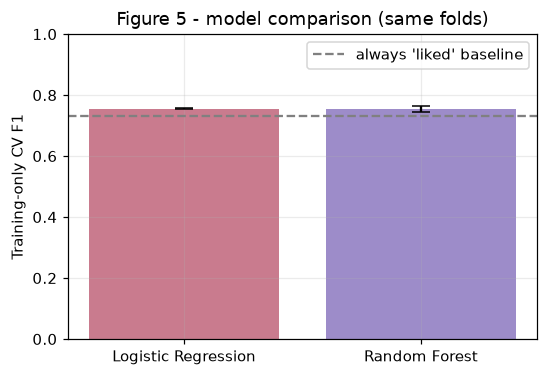

In [11]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=False)
folds = list(cv.split(X_train, y_train, groups=g_train))

cv_f1, rows = {}, []
for name, model in models.items():
    cv_f1[name] = cross_val_score(model, X_train, y_train, cv=folds, scoring="f1")
    oof_proba = cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
    oof_label = (oof_proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, oof_label, labels=[0, 1]).ravel()
    rows.append({"model": name, "F1 fold 1": cv_f1[name][0], "F1 fold 2": cv_f1[name][1], "F1 fold 3": cv_f1[name][2],
                 "mean F1": cv_f1[name].mean(), "SD": cv_f1[name].std(),
                 "precision": precision_score(y_train, oof_label), "recall": recall_score(y_train, oof_label),
                 "ROC-AUC": roc_auc_score(y_train, oof_proba), "TN": tn, "FP": fp, "FN": fn, "TP": tp})

baseline = DummyClassifier(strategy="constant", constant=1)      # always answers "liked"
baseline_f1 = cross_val_score(baseline, X_train, y_train, cv=folds, scoring="f1")

cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))
print("Baseline (always 'liked') mean F1:", round(baseline_f1.mean(), 3))

plt.figure(figsize=(5.5, 3.6))
plt.bar(list(cv_f1), [v.mean() for v in cv_f1.values()], yerr=[v.std() for v in cv_f1.values()],
        capsize=6, color=["#c97b8e", "#9d8cc9"])
plt.axhline(baseline_f1.mean(), color="gray", linestyle="--", label="always 'liked' baseline")
plt.ylim(0, 1); plt.ylabel("Training-only CV F1"); plt.title("Figure 5 - model comparison (same folds)"); plt.legend()
plt.show()

**What the result means.**

| Model | mean CV F1 | SD |
|---|---|---|
| Logistic Regression | 0.756 | 0.003 |
| Random Forest | 0.754 | 0.010 |
| Baseline: always "liked" | 0.733 | - |

Both models are better than the baseline, but only by a few F1 points, and the two models are very close to each other
(the difference is about the size of one standard deviation). F1 hides part of the progress here because the positive class is the majority;
ROC-AUC (about 0.74 in cross-validation, where 0.5 is random guessing) shows that the models really rank viewers better than chance.

## Step 8 - Select the best model BEFORE looking at the test set

Rule from the worksheet: choose the model with the higher **mean cross-validation F1** on training data.
We do not choose by test results.

In [12]:
best_name = max(cv_f1, key=lambda name: cv_f1[name].mean())
best_model = models[best_name]
print("Selected model:", best_name, "| mean CV F1 =", round(cv_f1[best_name].mean(), 3))

Selected model: Logistic Regression | mean CV F1 = 0.756


## Step 9 - Final evaluation on the untouched test set

The selected pipeline is fitted on all training rows and evaluated **once** on the test rows.

Selected: Logistic Regression
               precision    recall  f1-score   support

not liked (0)       0.69      0.60      0.64       830
    liked (1)       0.73      0.80      0.77      1139

     accuracy                           0.72      1969
    macro avg       0.71      0.70      0.70      1969
 weighted avg       0.71      0.72      0.71      1969

Confusion matrix [[TN FP] [FN TP]]:
 [[496 334]
 [223 916]]
{'precision': 0.733, 'recall': 0.804, 'f1': 0.767, 'roc_auc': 0.786, 'accuracy': np.float64(0.717)}


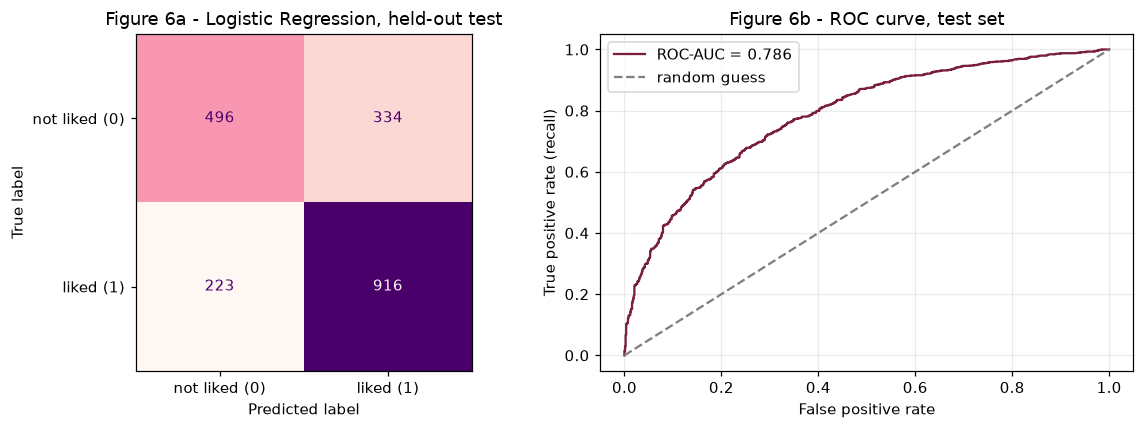

In [13]:
THRESHOLD = 0.5
best_model.fit(X_train, y_train)
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

print("Selected:", best_name)
print(classification_report(y_test, test_pred, target_names=["not liked (0)", "liked (1)"], zero_division=0))
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
final = {"precision": precision_score(y_test, test_pred), "recall": recall_score(y_test, test_pred),
         "f1": f1_score(y_test, test_pred), "roc_auc": roc_auc_score(y_test, test_proba),
         "accuracy": (test_pred == y_test).mean()}
print("Confusion matrix [[TN FP] [FN TP]]:\n", cm)
print({k: round(v, 3) for k, v in final.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["not liked (0)", "liked (1)"]).plot(ax=axes[0], cmap="RdPu", colorbar=False)
axes[0].grid(False); axes[0].set_title(f"Figure 6a - {best_name}, held-out test")
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color="#7a1f3d", label=f"ROC-AUC = {final['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guess")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("Figure 6b - ROC curve, test set"); axes[1].legend()
plt.tight_layout(); plt.show()

**What the result means (test set, 1,969 reviews, threshold 0.5).** Selected model: **Logistic Regression**.

| Metric | Value | Simple meaning |
|---|---|---|
| Confusion matrix | TN=496, FP=334, FN=223, TP=916 | rows = real class, columns = predicted class |
| Precision | 0.733 | when the model says "you will like it", it is right about 73% of the time |
| Recall | 0.804 | the model finds about 80% of the dramas that the viewer really liked |
| F1 | 0.767 | one number that balances precision and recall |
| ROC-AUC | 0.786 | if we take one liked and one not-liked review, the model gives the liked one a higher probability in about 79% of pairs (0.5 = guessing, 1.0 = perfect) |
| Accuracy | 0.717 | share of all correct answers (always answering "liked" would give 0.578) |

* **False positives (334)** - the model promised "you will like it" but the viewer scored the drama below 8.
* **False negatives (223)** - the model said "not for you" but the viewer actually liked it.
* The test F1 (0.767) is close to the cross-validation F1 (0.756), so the model does not look over-fitted.

For reference only (not used for the choice): Random Forest reaches F1 = 0.770 and ROC-AUC = 0.782 on the same test set. The two models are practically equal.

## Step 10 - Which features influence the predictions?

We use three views:
1. **Logistic Regression coefficients** (standardized) - direction and strength in a linear model.
2. **Random Forest impurity importance** - how much each feature helps the trees to split.
3. **Permutation importance** of the selected model on the test set - how much ROC-AUC drops when one feature is shuffled.

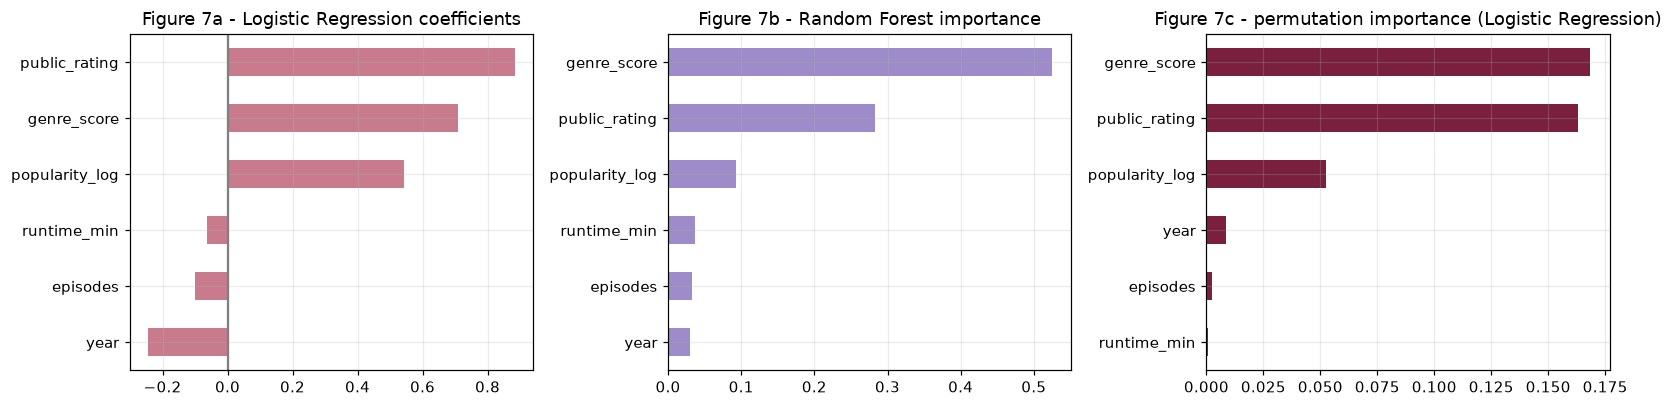

,LR coefficient,RF importance,AUC drop when shuffled
episodes,-0.099,0.033,0.002
genre_score,0.709,0.525,0.168
popularity_log,0.542,0.093,0.053
public_rating,0.883,0.283,0.163
runtime_min,-0.063,0.037,0.000
year,-0.245,0.030,0.009


In [14]:
for model in models.values():
    model.fit(X_train, y_train)

coefs = pd.Series(lr_model.named_steps["classifier"].coef_[0], index=FEATURES).sort_values()
importances = pd.Series(rf_model.named_steps["classifier"].feature_importances_, index=FEATURES).sort_values()
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
coefs.plot(kind="barh", ax=axes[0], color="#c97b8e"); axes[0].axvline(0, color="gray")
axes[0].set_title("Figure 7a - Logistic Regression coefficients")
importances.plot(kind="barh", ax=axes[1], color="#9d8cc9"); axes[1].set_title("Figure 7b - Random Forest importance")
perm_imp.plot(kind="barh", ax=axes[2], color="#7a1f3d"); axes[2].set_title(f"Figure 7c - permutation importance ({best_name})")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"LR coefficient": coefs, "RF importance": importances, "AUC drop when shuffled": perm_imp}).round(3))

**What the result means.**

* All three views put **`genre_score`** and **`public_rating`** clearly on top (their order differs a little between the views), followed by `popularity_log`.
  Shuffling `genre_score` lowers the test ROC-AUC by about 0.17; shuffling `runtime_min` or `episodes` changes almost nothing.
* Positive coefficients (`genre_score`, `public_rating`) raise the predicted chance of "liked" when the other features stay the same.
* `popularity_log` has a positive coefficient: for the same public rating, reviewers liked less famous dramas slightly more often.
  One possible reason is self-selection (people who search for a niche drama already expect to like it), but our data cannot prove the reason.
* **Important:** importance shows what the *model uses*, not what *causes* a person to like a drama. Correlated features (rating and popularity) share importance between them.

## Step 11 - Predict one NEW record, decision threshold and the cost of errors

A new case: a viewer who usually gives **9.0** to dramas of this genre considers a drama with **70-minute** episodes,
popularity rank **150**, public rating **8.6**, **16** episodes, released in **2022**.

In [15]:
new_record = pd.DataFrame([{"genre_score": 9.0, "runtime_min": 70.0, "popularity_rank": 150.0,
                            "public_rating": 8.6, "episodes": 16.0, "year": 2022}])
new_record["popularity_log"] = np.log10(new_record["popularity_rank"])
new_proba = best_model.predict_proba(new_record[FEATURES])[0, 1]

print("Probability of class 1 (liked):", round(new_proba, 3))
print("Decision threshold:", THRESHOLD)
print("Predicted class:", int(new_proba >= THRESHOLD), "->", "LIKED" if new_proba >= THRESHOLD else "NOT LIKED")

Probability of class 1 (liked): 0.795
Decision threshold: 0.5
Predicted class: 1 -> LIKED


In [16]:
# What happens if we move the threshold? (out-of-fold TRAINING predictions - the test set is not reused)
oof = cross_val_predict(best_model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    label = (oof >= thr).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_train, label, labels=[0, 1]).ravel()
    rows.append({"threshold": thr, "precision": precision_score(y_train, label), "recall": recall_score(y_train, label),
                 "F1": f1_score(y_train, label), "false positives": fp_, "false negatives": fn_})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

,threshold,precision,recall,F1,false positives,false negatives
0,0.3,0.628,0.957,0.758,2584,197
1,0.4,0.658,0.908,0.763,2146,418
2,0.5,0.699,0.822,0.756,1610,809
3,0.6,0.753,0.668,0.708,998,1511
4,0.7,0.803,0.447,0.574,499,2518


**What the result means.**

* The model gives the new record a probability of **0.795**. It is above the threshold 0.5, so the predicted class is **1 (liked)**.
  This is a software demonstration with invented input values, not a validation on a real new viewer.
* **Decision threshold.** The model outputs a probability; the threshold turns it into a yes/no answer. A higher threshold makes the model more careful:
  fewer false positives (higher precision) but more false negatives (lower recall). The table above shows this trade-off.
* **Cost of errors** (for a recommendation service):
  * a **false positive** = we recommend a drama and the viewer does not enjoy it: wasted evening (a K-Drama is 16+ hours), less trust in recommendations;
  * a **false negative** = we hide a drama that the viewer would have loved: a missed opportunity that nobody notices.
* We keep **0.5** as the default because it gives a balanced F1. If wasted time is considered more expensive, a threshold of 0.6 would be a reasonable choice
  (precision goes up, recall goes down). Nobody is harmed by either error, so there is no need for an extreme threshold.

## Step 12 - Conclusions

**Summary.** We used 9,840 real MyDramaList reviews (4,277 viewers, 1,066 Korean dramas) from two public Kaggle datasets to predict whether a viewer scores a drama 8 or higher.
We split the data 80/20 by viewer, fitted the imputer and the scaler only inside pipelines, and compared Logistic Regression with Random Forest using the same stratified 3-fold cross-validation.
The model selected by mean validation F1 was **Logistic Regression** (mean CV F1 0.756; the other model 0.754).
On the held-out test set it reached **F1 = 0.767, precision = 0.733, recall = 0.804 and ROC-AUC = 0.786**, with 334 false positives and 223 false negatives.
The most influential features were `genre_score` and `public_rating`.

**Limitations**

1. **Self-selected reviewers.** People who write reviews are more active and more positive than ordinary viewers; results may not transfer to all viewers.
2. **Cold start.** For 33% of the rows the viewer has no history, so `genre_score` is filled with the training median. Predictions for new viewers are weaker.
3. **No time stamps.** `genre_score` uses the viewer's other reviews without knowing which was written first, and `public_rating` is a 2023 snapshot that also contains (as a tiny part) the reviewers' own scores. A real system must use only past information.
4. **The label is a simplification.** "Score of 8 or more" is our definition of "liked"; a different threshold would change the classes.
5. **Modest gain.** The models are only a few F1 points above the "always liked" baseline; ROC-AUC of about 0.79 is useful but far from perfect.
6. **Licence.** Source B does not state a licence; we use it for a classroom project only.

**Risks.** A recommender trained on such data may push already popular, highly rated dramas and hide niche ones (popularity bias). Feature importance must not be read as causation.

**Realistic improvements.** (1) Add review dates and build `genre_score` only from earlier reviews; (2) add per-genre scores and tags (for example one score for Romance, one for Thriller);
(3) collect ratings from ordinary watch-lists, not only written reviews; (4) tune the threshold with a real cost estimate; (5) try gradient boosting and calibrate the probabilities.

**Reproducibility.** The split and the folds are deterministic (no shuffling); `SEED = 42` is used for both models. Run all cells from top to bottom in Google Colab; the data is downloaded automatically.

### Answers to the worksheet questions
* **Public labelled dataset vs synthetic practice dataset?** Here the labels were written by real people, so the results describe real behaviour (with its bias). Synthetic labels only describe our own assumptions.
* **Features and exact target?** Six numerical features (`genre_score`, `runtime_min`, `popularity_log`, `public_rating`, `episodes`, `year`); target `liked` = 1 if the viewer's overall score is 8 or more.
* **Why must the split come before preprocessing?** Otherwise the median and the scaling numbers would be calculated with test rows, and information from the test set would leak into training.
* **Which model has the higher CV F1?** Logistic Regression (0.756 against 0.754).
* **Test false positives and false negatives?** FP = 334, FN = 223.
* **What does the importance plot tell us, and what not?** It tells which features the model relies on. It does not prove that these features cause people to like a drama.

### References
* Charuchinda, C. (2023). *Korean Drama from 2015-2023 with Actors & Reviews* [Data set]. Kaggle. CC0 Public Domain. https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist
* Rizki, N. (2023). *Top Korean Drama List (~1500)* [Data set]. Kaggle. https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500
* MyDramaList. https://mydramalist.com (original source of both datasets)
* Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.

In [17]:
# Key numbers of this run, saved so that the report and the website can be checked against the notebook.
import json
summary = {"rows": int(len(data)), "train_rows": int(len(train_idx)), "test_rows": int(len(test_idx)),
           "cv_f1_mean": {name: float(v.mean()) for name, v in cv_f1.items()},
           "selected_model": best_name, "test": {k: float(v) for k, v in final.items()},
           "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
           "new_record_probability": float(new_proba)}
with open("p1_notebook_results.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "rows": 9840,
  "train_rows": 7871,
  "test_rows": 1969,
  "cv_f1_mean": {
    "Logistic Regression": 0.7557622900466997,
    "Random Forest": 0.7541933232237016
  },
  "selected_model": "Logistic Regression",
  "test": {
    "precision": 0.7328,
    "recall": 0.8042142230026339,
    "f1": 0.7668480535789033,
    "roc_auc": 0.7861244803621863,
    "accuracy": 0.7171152869476892
  },
  "confusion_matrix": {
    "tn": 496,
    "fp": 334,
    "fn": 223,
    "tp": 916
  },
  "new_record_probability": 0.7949056087976747
}
